# 6. End-to-end worked example

A full pass through one design decision, using only the public library calls: **which waveform, and what front-end does it require, for this geometry?**

The tool's flow is always the same: define a `Scenario`, call `run_link_budget`, and read the results. The app and the report use the same function.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
# Run from the notebooks folder, or from the project root.
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

from bistatic_lb import Scenario, run_link_budget, plots

from bistatic_lb.report import build_report, write_docx, write_markdown
from bistatic_lb.sweeps import sweep, sweep_values
from bistatic_lb.tracker import run_tracker_monte_carlo

root = Path("..") if Path.cwd().name == "notebooks" else Path(".")
names = ["pulsed_lfm_uhf", "phase_coded_uhf", "zadoff_chu_uhf", "fm_vhf", "dab_vhf", "dvbt_uhf"]
results = {n: run_link_budget(Scenario.from_yaml(root / "scenarios" / f"{n}.yaml")) for n in names}

print(f"{'Scenario':30s}{'PA W':>7s}{'Window dB':>11s}{'Bits':>6s}{'Cancel dB':>11s}{'SINR dB':>9s}{'Pd':>7s}{'Range m':>9s}{'Pos m':>8s}")
for n, r in results.items():
    print(f"{r.scenario.name:30s}{r.frontend.pa_saturated_w:7.0f}{r.frontend.gain_window_db:11.1f}{r.frontend.required_adc_bits:6.1f}{r.frontend.digital_cancellation_needed_db:11.1f}{r.link.sinr_db:9.1f}{r.detection.pd:7.3f}{r.estimation.sigma_bistatic_range_m:9.2f}{r.estimation.position_rms_m:8.0f}")


Scenario                         PA W  Window dB  Bits  Cancel dB  SINR dB     Pd  Range m   Pos m
Pulsed LFM, 600 MHz              1000       15.1  14.0       14.8     27.8  0.952     4.74     202
Phase-coded noise, 600 MHz       1995       15.1  13.4       31.8     30.8  0.974     1.68     143
Zadoff-Chu, 600 MHz              1000       18.1  13.1       52.8     30.8  0.974     1.68     143
FM broadcast, 100 MHz            2000       15.2  10.0       21.8     48.1  1.000     9.16      38
DAB, 225 MHz                     5610       17.5  11.9       15.3     37.3  0.995     1.04     133
DVB-T, 600 MHz                   5610       16.4  14.2       24.8     27.8  0.944     0.63     203


Reading the table:

- Each VHF example has a low-frequency advantage on path loss, but it needs analog suppression before the ADC to have a usable gain window.
- **OFDM** needs a PA about 11 times its mean power, because of PAPR. Constant-envelope waveforms do not.
- **FM** has a range cell of about 6 km of bi-static path, because of its narrow bandwidth. Its strong SINR here hides this in the accuracy column, but two close targets would not separate.

Note that these examples use different transmit powers and array sizes, so this compares complete example designs, not waveforms alone. For a like-for-like comparison, use the Trade-offs page of the app.

## Pick one, and explore it

Take DVB-T at 600 MHz, and see how the margin depends on target range and RCS.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


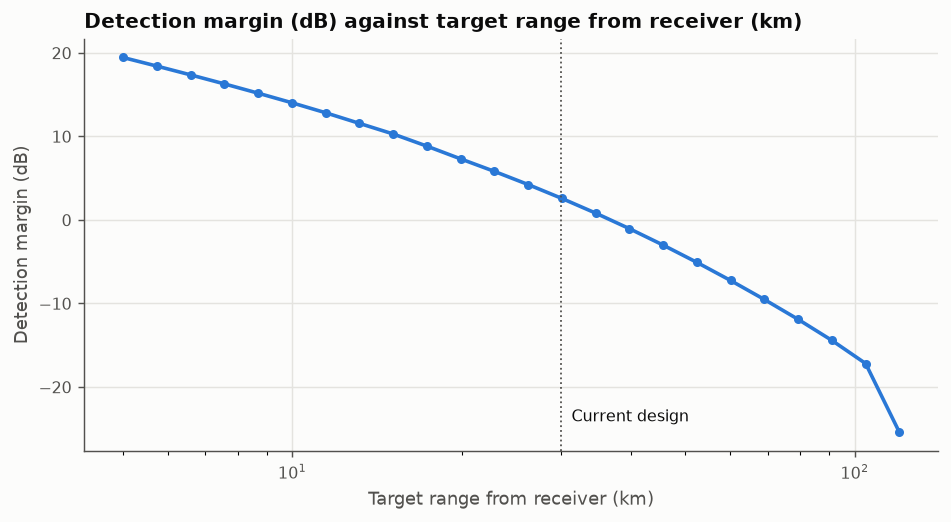

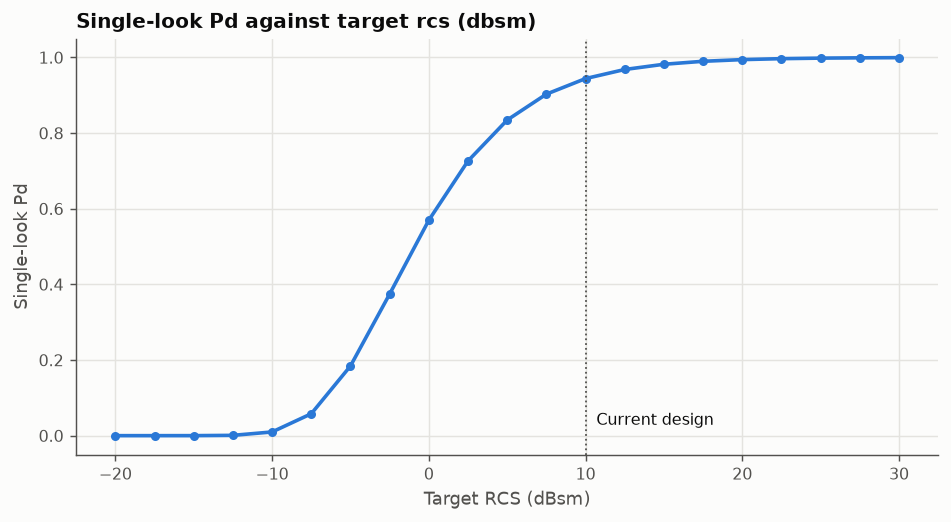

In [2]:
s = results["dvbt_uhf"].scenario
x, y = sweep(s, "geometry.target_range_rx_km", sweep_values("geometry.target_range_rx_km", 5, 120, 24), "Detection margin (dB)")
plots.sweep_line(x, y, "Target range from receiver (km)", "Detection margin (dB)", s.geometry.target_range_rx_km); plt.show()
x, y = sweep(s, "target.rcs_dbsm", np.linspace(-20, 30, 21), "Single-look Pd")
plots.sweep_line(x, y, "Target RCS (dBsm)", "Single-look Pd", s.target.rcs_dbsm); plt.show()


## Stress the front-end: a shorter baseline

The direct signal grows quickly as the baseline shrinks, and the gain window closes.

In [3]:
for b in (40, 20, 10, 5, 2):
    r = run_link_budget(s.with_value("geometry.baseline_km", float(b)))
    print(f"Baseline {b:3d} km: maximum direct {r.direct.element_maximum_dbm:6.1f} dBm, window {r.frontend.gain_window_db:6.1f} dB, need {r.frontend.required_adc_bits:5.1f} bits")
print()
print("Fix with 30 dB of analog cancellation at 5 km:")
r = run_link_budget(s.with_value("geometry.baseline_km", 5.0).with_value("frontend.analog_canceller_db", 30.0))
print(f"  window {r.frontend.gain_window_db:.1f} dB, need {r.frontend.required_adc_bits:.1f} bits")


Baseline  40 km: maximum direct  -54.0 dBm, window   22.6 dB, need  15.4 bits


Baseline  20 km: maximum direct  -47.8 dBm, window   16.4 dB, need  14.2 bits


Baseline  10 km: maximum direct  -39.1 dBm, window    7.7 dB, need  14.8 bits


Baseline   5 km: maximum direct  -33.1 dBm, window    1.7 dB, need   inf bits


Baseline   2 km: maximum direct  -26.1 dBm, window   -5.3 dB, need   inf bits

Fix with 30 dB of analog cancellation at 5 km:


  window 31.7 dB, need 14.2 bits


## Finalize, and report

This writes the same `.docx` and `.md` the app exports, with figures embedded.

..\reports\example_dvbt.docx


..\reports\example_dvbt.md


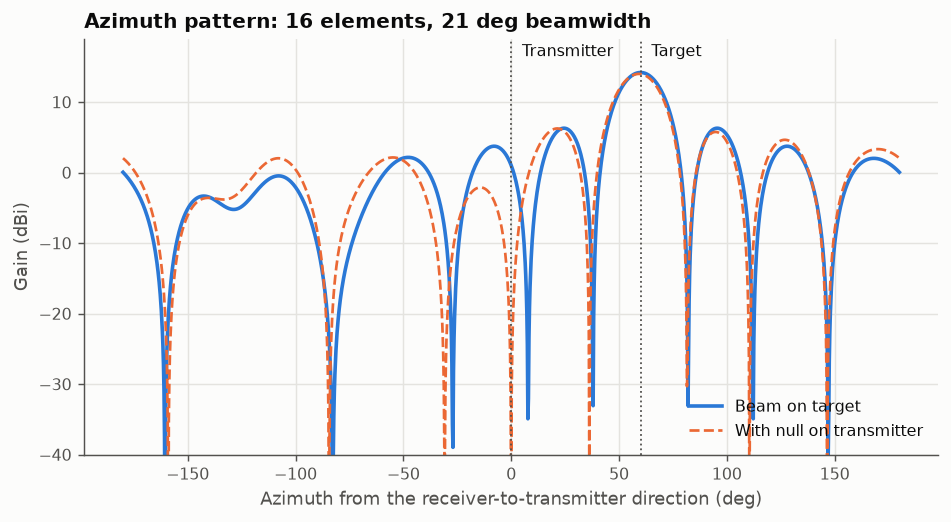

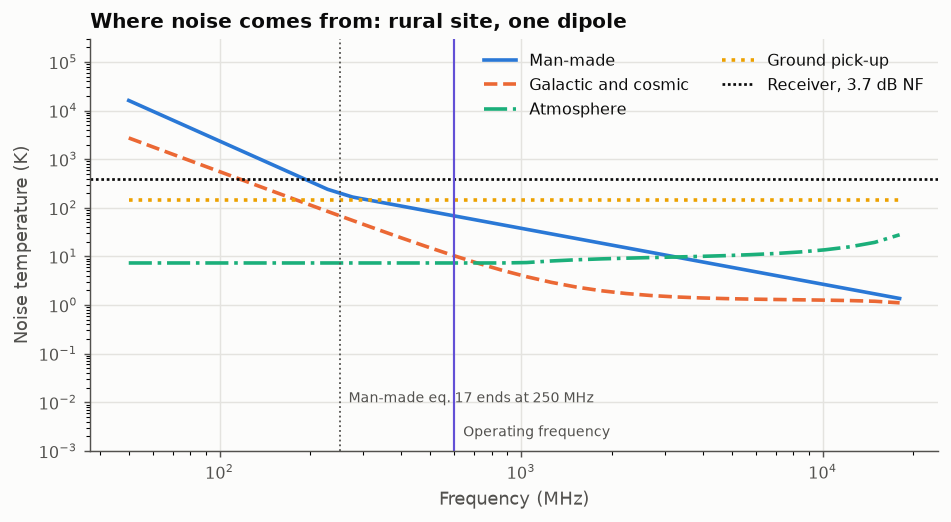

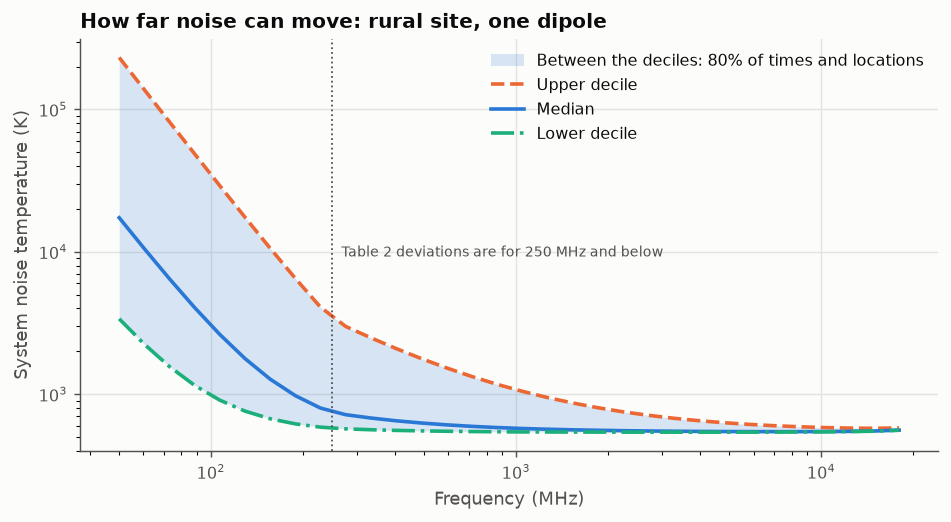

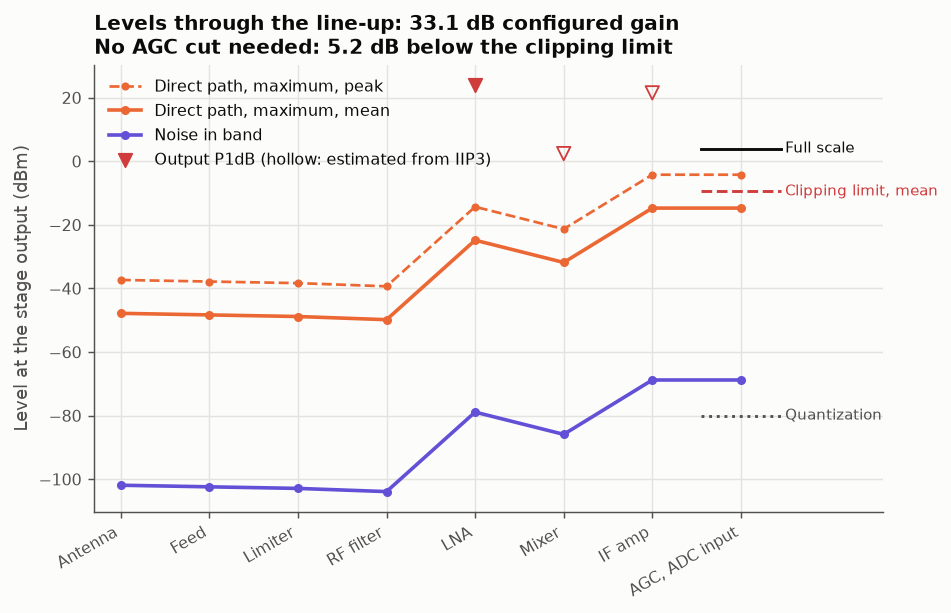

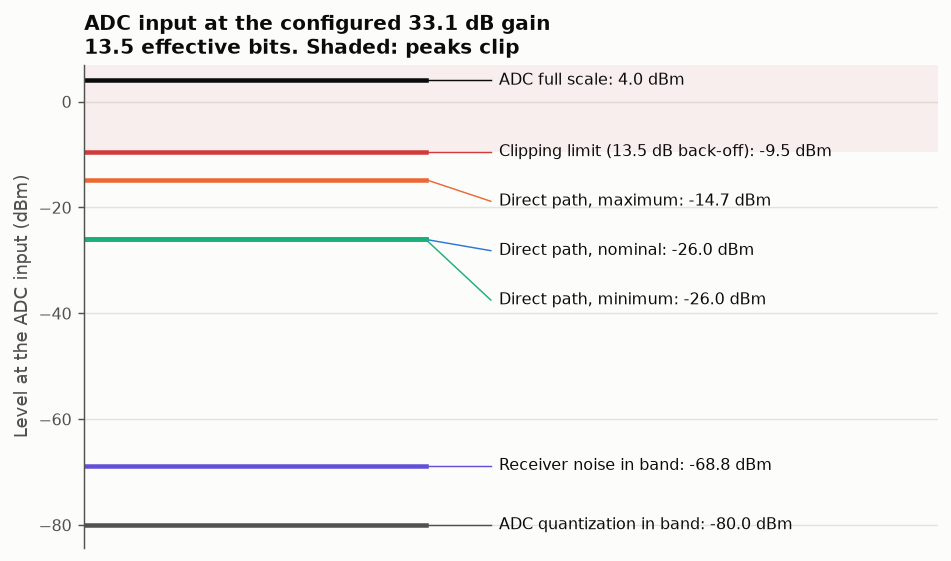

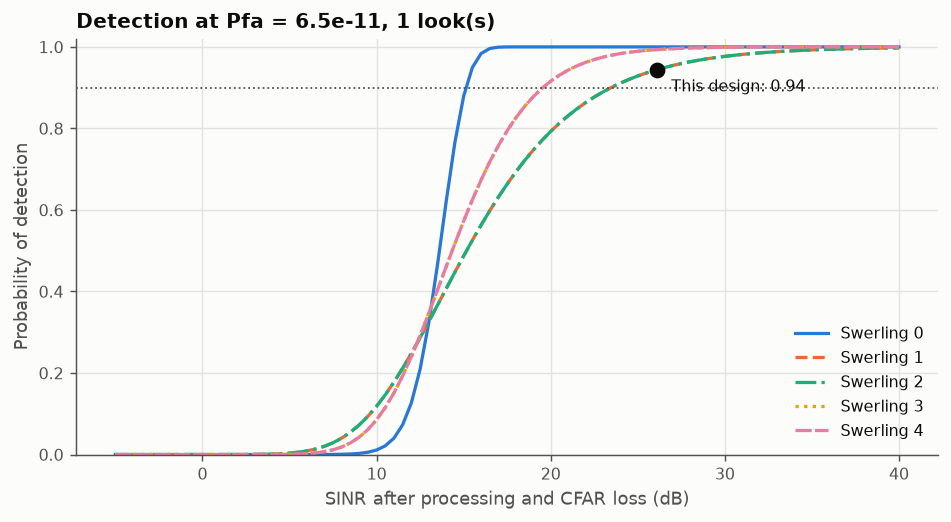

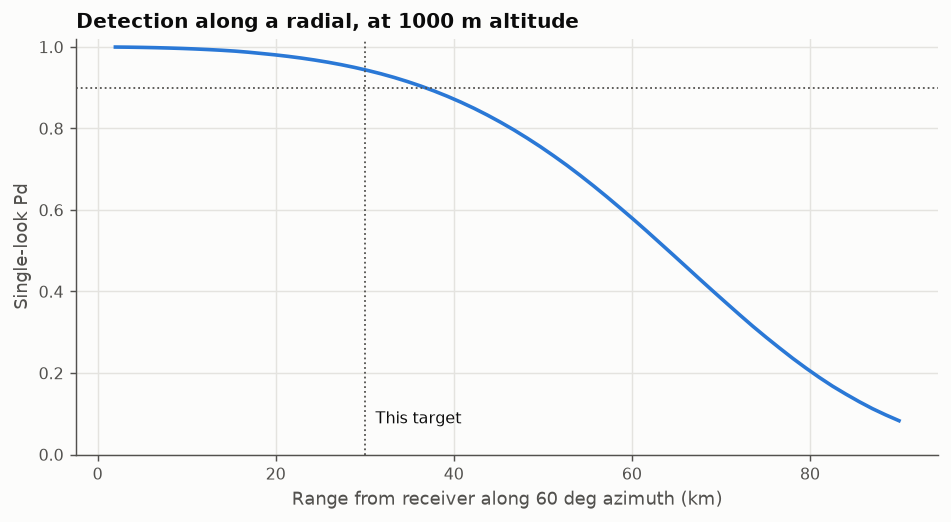

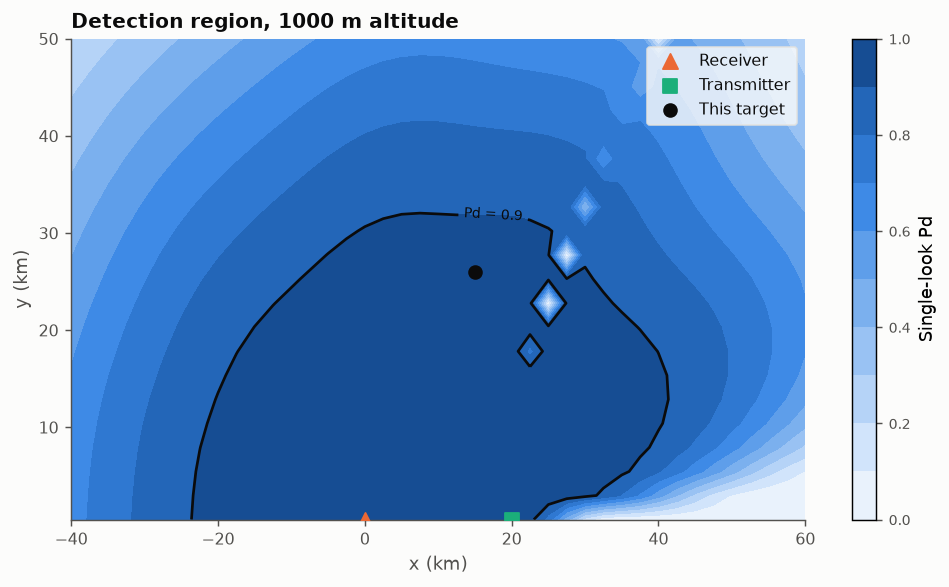

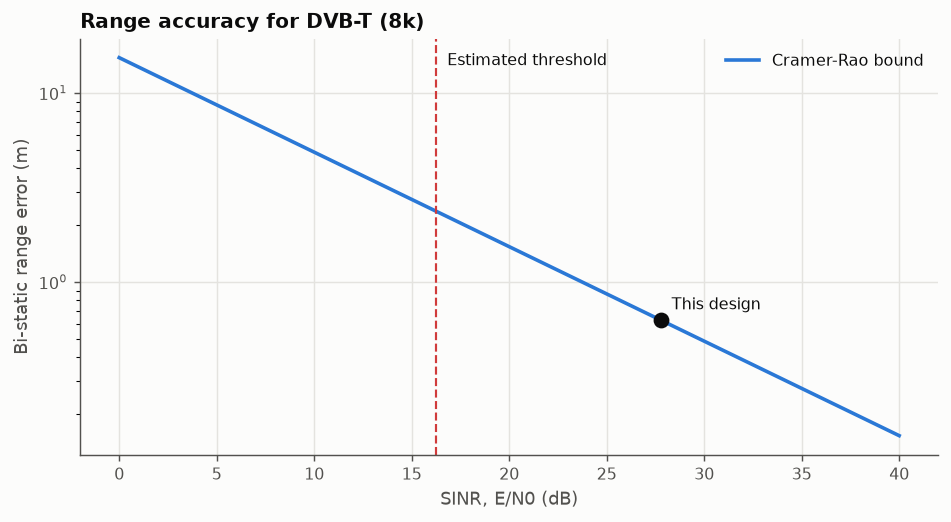

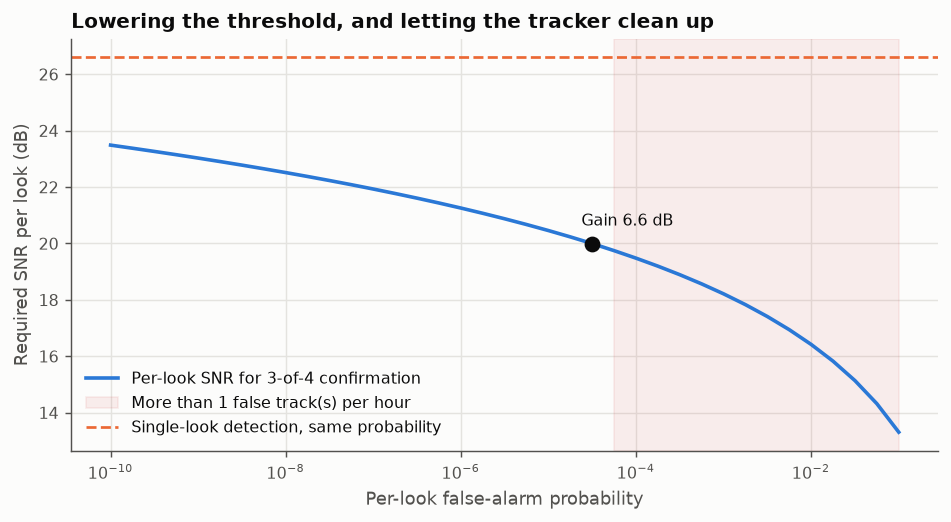

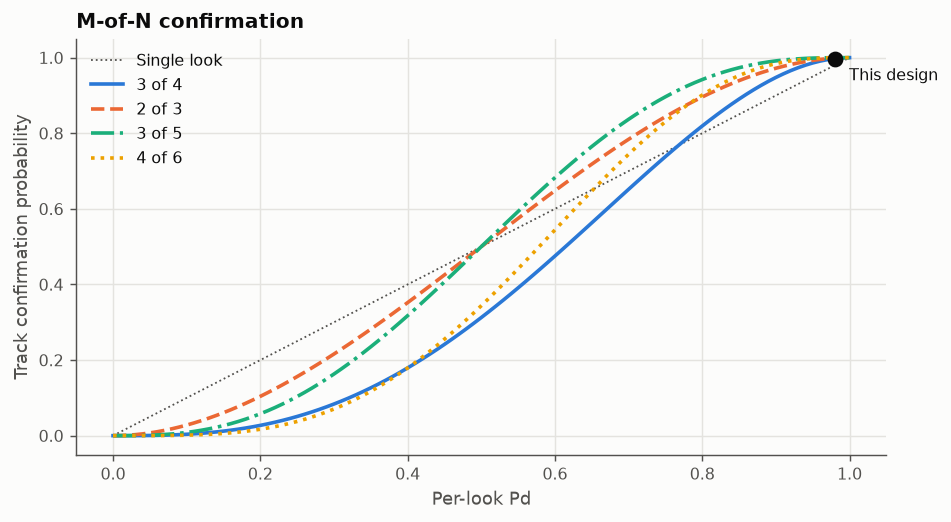

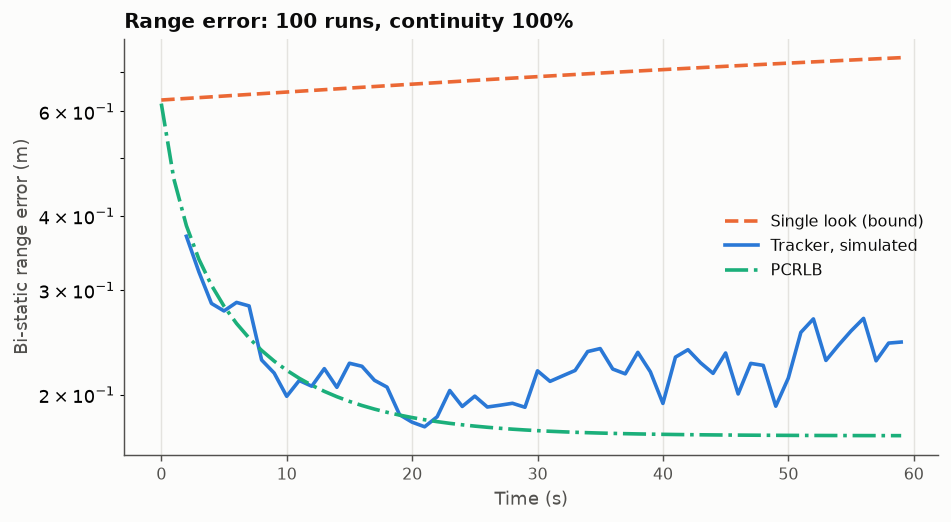

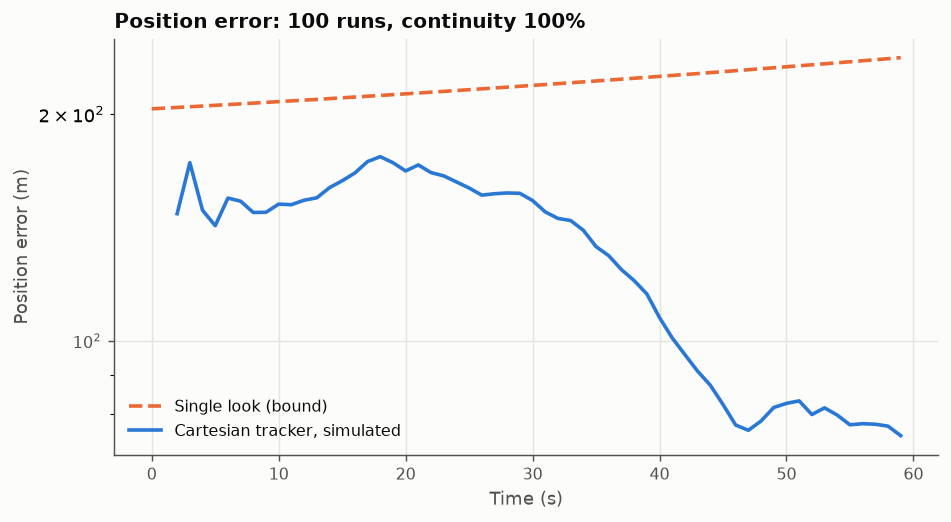

In [4]:
s.monte_carlo.runs = 100
r = run_link_budget(s)
mc = run_tracker_monte_carlo(r.analyzer, r.tracker.trade.best_pfa)
report = build_report(r, mc, status="Final", notes="Worked example from notebook 06.")
out = root / "reports"
print(write_docx(report, out / "example_dvbt.docx"))
print(write_markdown(report, out / "example_dvbt.md"))


## Check: same scenario, same numbers

The report, the app and this notebook all call `run_link_budget`, so a scenario saved as YAML reproduces the same results.

In [5]:
again = run_link_budget(Scenario.from_yaml(s.to_yaml()))
assert again.metrics == r.metrics
print("YAML round trip reproduces every metric exactly.")


YAML round trip reproduces every metric exactly.
